# Why the selected ML policy lagged

Was the primary shortfall already present before costs, and which fund contributions reconcile it?

This notebook reviews saved retrospective evidence. New descriptive calculations are post-study analysis, not new strategy selection or an untouched test.

In [1]:
from pathlib import Path
import json,sys,math,statistics
r=Path.cwd()
if not (r/'artifacts/research').exists(): r=r.parent
sys.path.insert(0,str(r/'src'));sys.path.insert(0,str(r))
from scripts.review_visuals import table,figure,lines,bars
if 'display_bundle' not in globals():
 from IPython.display import display
 def display_bundle(data): display(data,raw=True)
b=json.loads((r/'artifacts/research/public_bundle.json').read_text());a=b['analysis']
p=json.loads((r/'artifacts/review/polish.json').read_text());chosen=b['selected']
print('Saved test:',b['as_of'],'Selected:',chosen,'Post-study review:',p['review_date'])

Saved test: 2025-12-31 Selected: stumps_24 Post-study review: 2026-11-25


## Gross-to-net comparative bridge

Every bridge uses the same initial capital. The friction effect is net gap minus zero-cost gap, including compounding/sizing effects.

In [2]:
display_bundle(table(['Comparator','Zero-cost NAV gap ($)','Differential friction ($)','Net NAV gap ($)'],[[n,round(x['zero_cost_nav_gap'],2),round(x['differential_friction_effect'],2),round(x['net_nav_gap'],2)] for n,x in p['comparisons'].items()]))
for x in p['comparisons'].values():assert abs(x['zero_cost_nav_gap']+x['differential_friction_effect']-x['net_nav_gap'])<1e-7

Comparator,Zero-cost NAV gap ($),Differential friction ($),Net NAV gap ($)
momentum_63,-3045.28,82.93,-2962.35
equal_weight,-4359.58,-2306.72,-6666.3


## Relative wealth over the full test

A relative wealth ratio is not the cumulative sum of monthly excess returns.

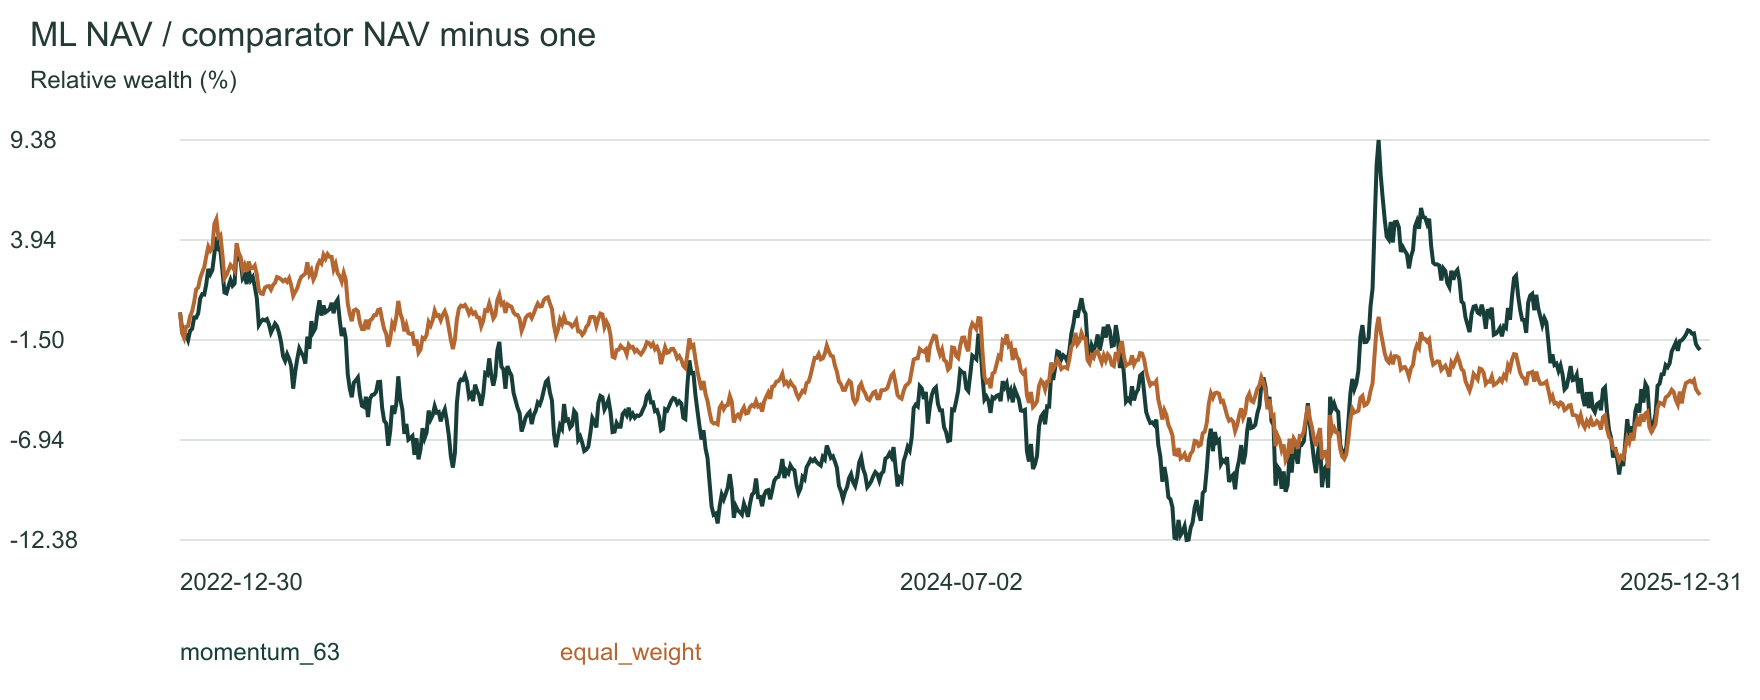

In [3]:
display_bundle(figure(lines('ML NAV / comparator NAV minus one',[x['date'] for x in p['comparisons']['momentum_63']['relative_wealth']],{n:[100*x['relative_wealth'] for x in v['relative_wealth']] for n,v in p['comparisons'].items()},'Relative wealth (%)')))

## Fund-level contribution differences

This identity combines holdings, timing and execution; it is not a Brinson decomposition.

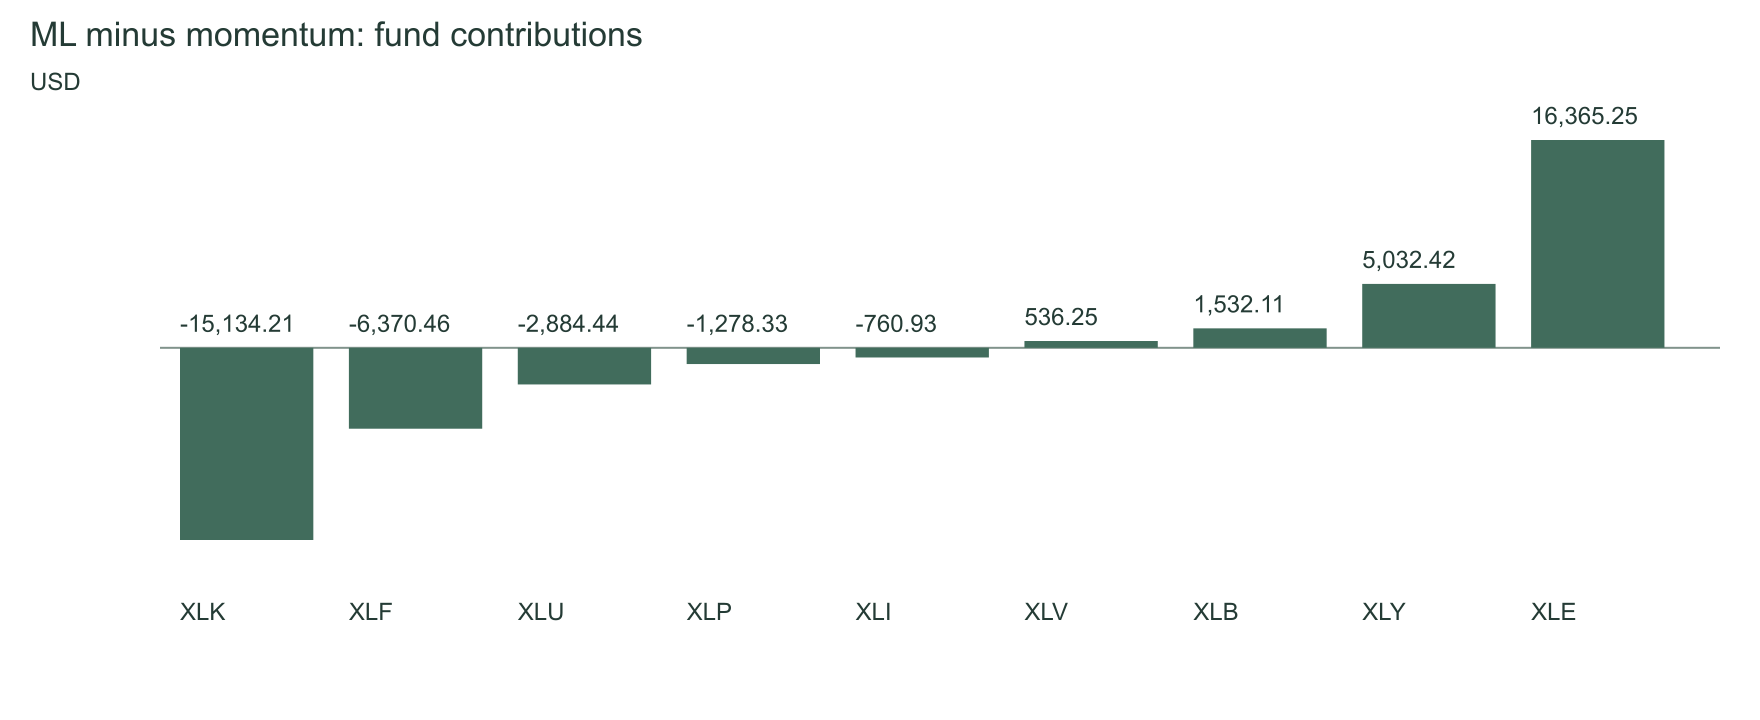

In [4]:
x=p['comparisons']['momentum_63'];display_bundle(figure(bars('ML minus momentum: fund contributions',[v['asset'] for v in x['sectors']],[v['difference'] for v in x['sectors']],'USD')));assert abs(sum(v['difference'] for v in x['sectors'])-x['net_nav_gap'])<1e-6

## Distribution of monthly differences

Winning more individual months need not imply a higher compounded terminal NAV.

In [5]:
display_bundle(table(['Comparator','Positive months / 36','Mean monthly difference','Relative terminal wealth'],[[n,str(x['positive_months'])+'/36',f'{x["mean_monthly_excess"]:.4%}',f'{x["relative_terminal_wealth"]:.2%}'] for n,x in p['comparisons'].items()]));print(p['interpretation']['momentum_63']);print(p['interpretation']['equal_weight'])

Comparator,Positive months / 36,Mean monthly difference,Relative terminal wealth
momentum_63,17/36,-0.0315%,-2.05%
equal_weight,20/36,-0.0920%,-4.49%


ML also trails momentum in the zero-cost rerun. Differential friction slightly narrows this gap, so extra trading costs alone do not explain the primary shortfall.
ML trails equal weight before costs; its larger friction drag further widens that shortfall.


## Interpretation

Against momentum, the zero-cost shortfall is about \$3,045 and differential friction offsets about \$83, leaving a \$2,962 net shortfall. Against equal weight, both gross allocation outcomes and higher friction contribute. These are descriptive identities, not isolated causal explanations.